# Định lý Bayes & Naive Bayes (Gaussian)

Naive Bayes là thuật toán phân loại theo hướng sinh học (Generative Model) dựa trên Định lý Bayes. Thay vì đi tìm đường biên phân chia (như SVM, Logistic), nó mô hình hóa trực tiếp phân phối xác suất của từng lớp dữ liệu.

**1. Định lý Bayes:**
Xác suất hậu nghiệm (Posterior) của một lớp $c$ khi biết dữ liệu $x$ là:
$$P(y=c | x) = \frac{P(x | y=c) \cdot P(y=c)}{P(x)}$$
Vì mẫu số $P(x)$ giống nhau cho mọi lớp, ta chỉ cần tối đa hóa tử số: $P(x | y=c) \cdot P(y=c)$

**2. Giả định "Ngây thơ" (Naive):**
Thuật toán giả định rằng tất cả các đặc trưng (features) đều **độc lập có điều kiện** với nhau khi đã biết nhãn $y$. Khi đó, Likelihood $P(x|y=c)$ được tách thành tích các xác suất đơn lẻ:
$$P(x | y=c) = \prod_{i=1}^D P(x_i | y=c)$$

**3. Gaussian Naive Bayes:**
Khi làm việc với dữ liệu liên tục, ta giả định mỗi đặc trưng tuân theo phân phối Chuẩn (Gaussian) $N(\mu, \sigma^2)$ trong từng lớp:
$$P(x_i | y=c) = \frac{1}{\sqrt{2\pi\sigma_{c,i}^2}} \exp\left(-\frac{(x_i - \mu_{c,i})^2}{2\sigma_{c,i}^2}\right)$$
Để tránh hiện tượng tràn số dưới (underflow) khi nhân nhiều xác suất nhỏ, ta sẽ dùng **Log-Probability** (tổng log thay vì tích).

In [1]:
import numpy as np

class GaussianNaiveBayes:
    """Thuật toán Gaussian Naive Bayes code hoàn toàn bằng NumPy Vector hóa."""
    def __init__(self):
        self.classes = None
        self.mean = None
        self.var = None
        self.priors = None

    def fit(self, X: np.ndarray, y: np.ndarray):
        X, y = np.asarray(X), np.asarray(y)
        self.classes = np.unique(y)
        n_classes = len(self.classes)
        n_features = X.shape[1]

        # Khởi tạo các tham số phân phối cho từng lớp
        self.mean = np.zeros((n_classes, n_features))
        self.var = np.zeros((n_classes, n_features))
        self.priors = np.zeros(n_classes)

        for idx, c in enumerate(self.classes):
            X_c = X[y == c]
            # Tính Kỳ vọng (mean) và Phương sai (variance) cho lớp c
            self.mean[idx, :] = X_c.mean(axis=0)
            # Cộng thêm 1e-9 (epsilon) để tránh lỗi chia cho 0 nếu variance = 0
            self.var[idx, :] = X_c.var(axis=0) + 1e-9
            # Xác suất tiên nghiệm P(y=c)
            self.priors[idx] = X_c.shape[0] / float(X.shape[0])
            
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        X = np.asarray(X)
        posteriors = np.zeros((X.shape[0], len(self.classes)))

        for idx, c in enumerate(self.classes):
            prior = np.log(self.priors[idx])
            
            # Tính Log-Likelihood dựa trên hàm mật độ xác suất Gaussian (PDF)
            # log(P(x|c)) = -0.5 * log(2*pi*var) - 0.5 * ((x - mean)^2 / var)
            log_likelihood = -0.5 * np.sum(np.log(2 * np.pi * self.var[idx, :])) \
                             -0.5 * np.sum(((X - self.mean[idx, :]) ** 2) / self.var[idx, :], axis=1)
            
            # Posterior = log(Prior) + log(Likelihood)
            posteriors[:, idx] = prior + log_likelihood

        # Trả về nhãn có xác suất cao nhất
        return self.classes[np.argmax(posteriors, axis=1)]

Metric               | Scratch         | Sklearn        
-------------------------------------------------------
Accuracy Score       | 1.0000          | 1.0000         
Time (ms)            | 0.00            | 0.00           


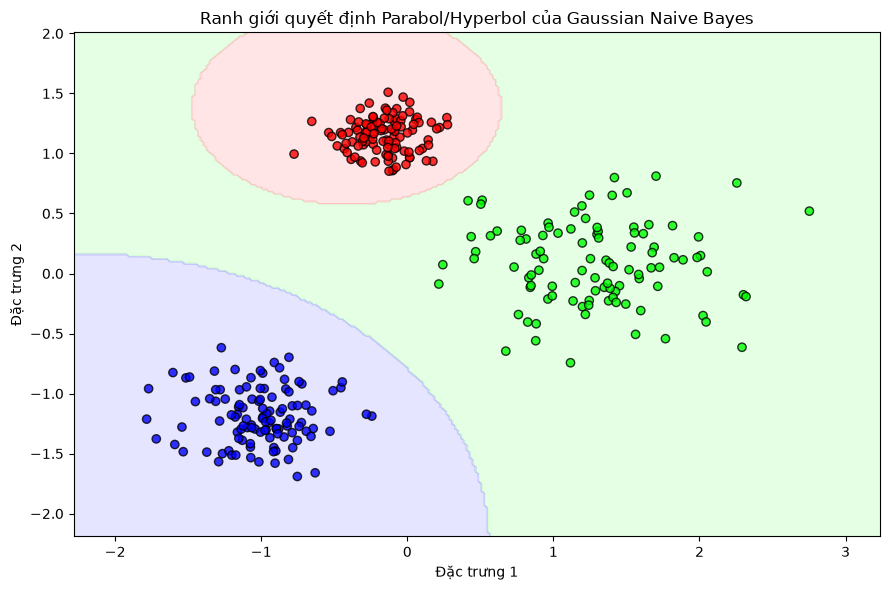

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.datasets import make_blobs
from utils.metrics import accuracy_score
from utils.preprocessing import StandardScaler, train_test_split

# 1. Sinh dữ liệu 3 lớp (Tạo độ lệch chuẩn khác nhau để xem ranh giới phi tuyến của Bayes)
X, y = make_blobs(n_samples=400, centers=3, n_features=2, random_state=42, cluster_std=[1.0, 2.5, 1.5])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Naive Bayes không bắt buộc phải chuẩn hóa (vì tính variance độc lập)
# nhưng chuẩn hóa giúp hiển thị đồ thị đẹp hơn
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Huấn luyện model Scratch
t0 = time.time()
model_scratch = GaussianNaiveBayes().fit(X_train_scaled, y_train)
t_scratch = (time.time() - t0) * 1000

# 4. Huấn luyện model Sklearn
t0 = time.time()
model_sklearn = GaussianNB().fit(X_train_scaled, y_train)
t_sklearn = (time.time() - t0) * 1000

# 5. Đánh giá
y_pred_scratch = model_scratch.predict(X_test_scaled)
y_pred_sklearn = model_sklearn.predict(X_test_scaled)

print(f"{'Metric':<20} | {'Scratch':<15} | {'Sklearn':<15}")
print("-" * 55)
print(f"{'Accuracy Score':<20} | {accuracy_score(y_test, y_pred_scratch):<15.4f} | {accuracy_score(y_test, y_pred_sklearn):<15.4f}")
print(f"{'Time (ms)':<20} | {t_scratch:<15.2f} | {t_sklearn:<15.2f}")

# 6. Trực quan hóa Decision Boundary
plt.figure(figsize=(9, 6))
x_min, x_max = X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5
y_min, y_max = X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

Z = model_scratch.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

from matplotlib.colors import ListedColormap
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

plt.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
plt.scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], c=y_train, cmap=cmap_bold, edgecolors='k', alpha=0.8)
plt.title("Ranh giới quyết định Parabol/Hyperbol của Gaussian Naive Bayes")
plt.xlabel("Đặc trưng 1")
plt.ylabel("Đặc trưng 2")

plt.tight_layout()
plt.show()